# Autoregressive, diffusion, flow matching

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/04-autoregressive-diffusion-flow-matching/notebook.ipynb)

Companion to the article *Autoregressive, Diffusion, Flow Matching: Three Ways a Machine Writes Music*. We work the sampling arithmetic by hand, train a diffusion model and a flow matching model on the same toy problem, and time a real music model.

Runs on a CPU. The toy training takes about three minutes; the MusicGen section about two.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile "transformers>=4.45"

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import math, time, torch, torch.nn as nn
torch.manual_seed(0); np.set_printoptions(precision=2, suppress=True)

## 1. From scores to a choice: softmax, temperature, top-k

An autoregressive model outputs one raw score (a logit) per possible next token. Softmax turns scores into probabilities.

In [3]:
def softmax(logits):
    e = np.exp(logits - logits.max())
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.5, -1.0])
print("e^logit:      ", np.exp(logits), " total", round(np.exp(logits).sum(), 2))
print("probabilities:", softmax(logits))
for T in (0.5, 1.0, 2.0):
    print(f"temperature {T}:", softmax(logits / T))
p = softmax(logits); p[np.argsort(p)[:-2]] = 0            # top-k with k = 2: drop all but the two most likely
print("top-2:        ", p / p.sum())

e^logit:       [7.39 2.72 1.65 0.37]  total 12.12
probabilities: [0.61 0.22 0.14 0.03]
temperature 0.5: [0.84 0.11 0.04 0.  ]
temperature 1.0: [0.61 0.22 0.14 0.03]
temperature 2.0: [0.43 0.26 0.21 0.1 ]
top-2:         [0.73 0.27 0.   0.  ]


## 2. Classifier-free guidance

Run the model with and without the prompt, and exaggerate the difference: `guided = unprompted + scale × (prompted − unprompted)`.

In [4]:
without_prompt = np.array([1.0, 1.0, 1.0, 0.0])
with_prompt = np.array([2.0, 1.0, 0.5, -1.0])
for scale in (1, 3, 10):
    guided = without_prompt + scale * (with_prompt - without_prompt)
    print(f"scale {scale:2d}: logits {guided}  probabilities {softmax(guided)}")

scale  1: logits [ 2.   1.   0.5 -1. ]  probabilities [0.61 0.22 0.14 0.03]
scale  3: logits [ 4.   1.  -0.5 -3. ]  probabilities [0.94 0.05 0.01 0.  ]
scale 10: logits [ 11.   1.  -4. -10.]  probabilities [1. 0. 0. 0.]


## 3. Diffusion and flow matching, by hand

Diffusion mixes signal and noise: `noisy = √a × x + √(1 − a) × ε`. Flow matching puts a point on the straight line from noise to data and learns the velocity along it.

In [5]:
x, eps, a = 5.0, -1.0, 0.5
noisy = math.sqrt(a) * x + math.sqrt(1 - a) * eps
print(f"diffusion: noisy = {noisy:.2f}; knowing the noise recovers x = {(noisy - math.sqrt(1 - a) * eps) / math.sqrt(a):.1f}")

x1, x0, t = 5.0, -1.0, 0.25
print(f"flow matching: point at t={t} is {(1 - t) * x0 + t * x1}, velocity is {x1 - x0}")
pos, path = x0, [x0]
for _ in range(4):
    pos += 0.25 * (x1 - x0); path.append(pos)             # four Euler steps
print("four Euler steps:", path)

diffusion: noisy = 2.83; knowing the noise recovers x = 5.0
flow matching: point at t=0.25 is 0.5, velocity is 6.0
four Euler steps: [-1.0, 0.5, 2.0, 3.5, 5.0]


## 4. Head to head on a toy problem

The data: points in eight tight clusters on a ring. Three small networks, identical in size and training time:

- diffusion predicting the noise, set up without special care
- diffusion predicting `v`, the well-behaved target
- flow matching

`TRAIN_STEPS = 20000` reproduces the article. Lower it for a faster, rougher run.

In [6]:
TRAIN_STEPS, BATCH = 20000, 1024
centers = torch.stack([2 * torch.cos(torch.arange(8) * 2 * math.pi / 8), 2 * torch.sin(torch.arange(8) * 2 * math.pi / 8)], 1)

def data(n):
    return centers[torch.randint(0, 8, (n,))] + 0.1 * torch.randn(n, 2)

class Net(nn.Module):                                      # takes a position and a time, returns a 2-D vector
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(2 + 16, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 2))
    def forward(self, x, t):
        freqs = 2 ** torch.arange(8, dtype=torch.float32) * math.pi
        emb = torch.cat([torch.sin(t[:, None] * freqs), torch.cos(t[:, None] * freqs)], 1)
        return self.f(torch.cat([x, emb], 1))

signal_level = lambda t: torch.cos(t * math.pi / 2) ** 2   # the noise schedule: "a" as a function of time (0 = clean, 1 = noise)

def train(loss_fn):
    net = Net(); opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(TRAIN_STEPS):
        loss = loss_fn(net); opt.zero_grad(); loss.backward(); opt.step()
    return net

def loss_noise_prediction(net):
    x1 = data(BATCH); t = torch.rand(BATCH) * 0.999; eps = torch.randn(BATCH, 2); a = signal_level(t)[:, None]
    return ((net(a.sqrt() * x1 + (1 - a).sqrt() * eps, t) - eps) ** 2).mean()

def loss_v_prediction(net):
    x1 = data(BATCH); t = torch.rand(BATCH); eps = torch.randn(BATCH, 2); a = signal_level(t)[:, None]
    v = a.sqrt() * eps - (1 - a).sqrt() * x1
    return ((net(a.sqrt() * x1 + (1 - a).sqrt() * eps, t) - v) ** 2).mean()

def loss_flow_matching(net):
    x1 = data(BATCH); x0 = torch.randn(BATCH, 2); t = torch.rand(BATCH)
    xt = (1 - t[:, None]) * x0 + t[:, None] * x1           # point on the straight line
    return ((net(xt, t) - (x1 - x0)) ** 2).mean()          # target: the velocity

start = time.time()
noise_net, v_net, flow_net = train(loss_noise_prediction), train(loss_v_prediction), train(loss_flow_matching)
print(f"trained three models in {time.time() - start:.0f} s")

trained three models in 175 s


Samplers. Diffusion uses DDIM steps; flow matching uses Euler steps.

real data: 98.9% of points on a cluster

steps   diffusion, noise pred.   diffusion, v-pred.   flow matching
    2                   2%                   4%              7%
    4                  16%                  70%             77%


    8                  39%                  92%             93%

   16                  57%                  97%             96%


   32                  73%                  98%             97%


   64                  83%                  97%             97%


  128                  90%                  98%             97%


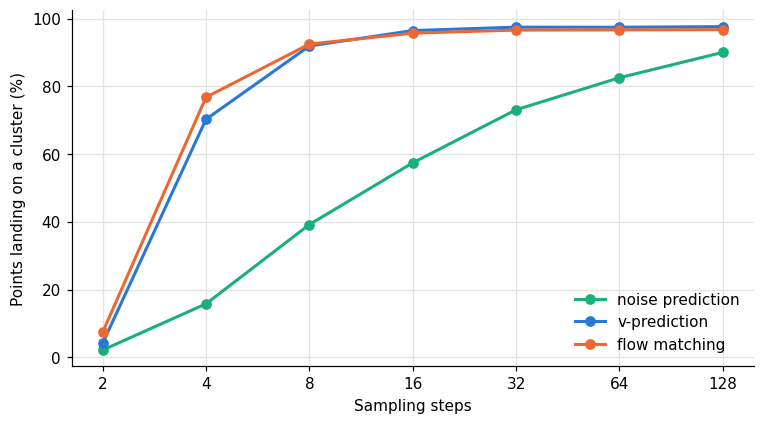

In [7]:
@torch.no_grad()
def sample_noise_prediction(x, n):
    ts = torch.linspace(0.999, 0, n + 1)
    for i in range(n):
        a, a_next = signal_level(ts[i]), signal_level(ts[i + 1])
        eps = noise_net(x, ts[i].expand(len(x)))
        x_clean = (x - (1 - a).sqrt() * eps) / a.sqrt()                 # divides by a tiny number at high noise
        x = a_next.sqrt() * x_clean + (1 - a_next).sqrt() * eps
    return x

@torch.no_grad()
def sample_v_prediction(x, n, keep_path=False):
    ts = torch.linspace(1.0, 0, n + 1); path = [x.clone()]
    for i in range(n):
        a, a_next = signal_level(ts[i]).clamp(0, 1), signal_level(ts[i + 1]).clamp(0, 1)
        v = v_net(x, ts[i].expand(len(x)))
        x_clean = a.sqrt() * x - (1 - a).sqrt() * v; eps = (1 - a).sqrt() * x + a.sqrt() * v
        x = a_next.sqrt() * x_clean + (1 - a_next).sqrt() * eps; path.append(x.clone())
    return (x, torch.stack(path)) if keep_path else x

@torch.no_grad()
def sample_flow(x, n, keep_path=False):
    path = [x.clone()]
    for i in range(n):
        x = x + flow_net(x, torch.full((len(x),), i / n)) / n            # one Euler step
        path.append(x.clone())
    return (x, torch.stack(path)) if keep_path else x

on_cluster = lambda x: ((x[:, None] - centers[None]).norm(dim=2).min(1).values < 0.3).float().mean().item()
print(f"real data: {100 * on_cluster(data(10000)):.1f}% of points on a cluster\n")
noise = torch.randn(10000, 2); steps = [2, 4, 8, 16, 32, 64, 128]; curves = {"noise prediction": [], "v-prediction": [], "flow matching": []}
print("steps   diffusion, noise pred.   diffusion, v-pred.   flow matching")
for n in steps:
    r = [on_cluster(f(noise.clone(), n)) for f in (sample_noise_prediction, sample_v_prediction, sample_flow)]
    for k, v in zip(curves, r): curves[k].append(100 * v)
    print(f"{n:5d}   {100 * r[0]:17.0f}%   {100 * r[1]:17.0f}%   {100 * r[2]:12.0f}%")

fig, ax = plt.subplots(figsize=(8, 4.2))
for (label, ys), color in zip(curves.items(), (AQUA, BLUE, ORANGE)): ax.plot(steps, ys, "-o", color=color, label=label)
ax.set_xscale("log", base=2); ax.set_xticks(steps); ax.set_xticklabels(steps)
ax.set_xlabel("Sampling steps"); ax.set_ylabel("Points landing on a cluster (%)"); ax.legend(frameon=False); plt.show()

The two well-configured models are nearly indistinguishable. Now the paths, with 200 small steps each.

typical sideways deviation: diffusion 23%, flow matching 12%


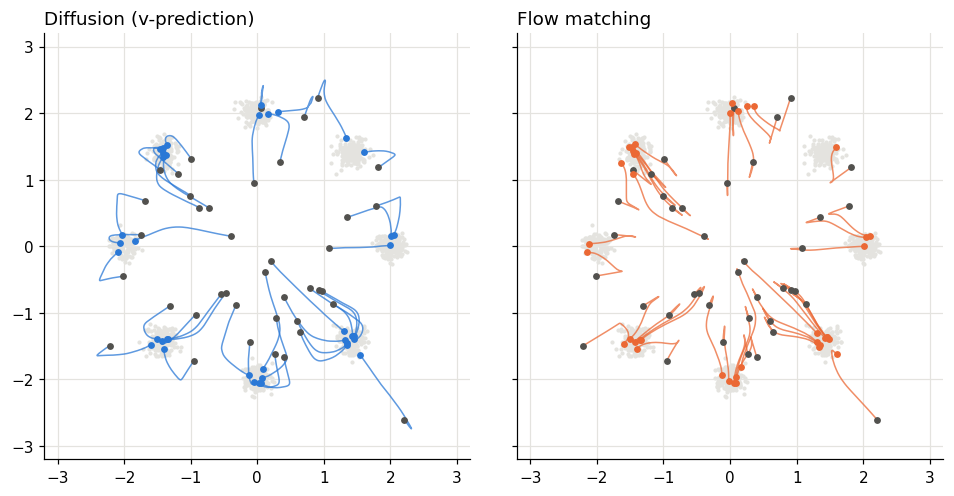

In [8]:
z = torch.randn(2000, 2)
_, path_d = sample_v_prediction(z.clone(), 200, True); _, path_f = sample_flow(z.clone(), 200, True)

def sideways_deviation(p):                                  # largest distance from the straight line, relative to distance travelled
    d = p[-1] - p[0]; L = d.norm(dim=1); u = d / L[:, None]; r = p - p[0]
    return ((r - (r * u).sum(2, keepdim=True) * u).norm(dim=2).max(0).values / L).median().item()
print(f"typical sideways deviation: diffusion {100 * sideways_deviation(path_d):.0f}%, flow matching {100 * sideways_deviation(path_f):.0f}%")

real = data(1500)
fig, axs = plt.subplots(1, 2, figsize=(9, 4.4), sharex=True, sharey=True)
for ax, p, title, color in ((axs[0], path_d, "Diffusion (v-prediction)", BLUE), (axs[1], path_f, "Flow matching", ORANGE)):
    ax.scatter(real[:, 0], real[:, 1], s=3, color=GRID)
    for j in range(40): ax.plot(p[:, j, 0], p[:, j, 1], color=color, lw=1, alpha=0.75)
    ax.scatter(p[0, :40, 0], p[0, :40, 1], s=12, color=INK2, zorder=3); ax.scatter(p[-1, :40, 0], p[-1, :40, 1], s=12, color=color, zorder=3)
    ax.set_title(title, loc="left"); ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2)
plt.tight_layout(); plt.show()

## 5. A real autoregressive model: MusicGen

50 frames per second, so `max_new_tokens=250` is five seconds. We time two lengths, switch guidance off, and compare sampling with greedy decoding.

In [9]:
import soundfile as sf
from transformers import AutoProcessor, MusicgenForConditionalGeneration, logging
logging.set_verbosity_error()

name = "facebook/musicgen-small"
proc = AutoProcessor.from_pretrained(name)
musicgen = MusicgenForConditionalGeneration.from_pretrained(name).eval()
inputs = proc(text=["lo-fi beat with warm electric piano"], padding=True, return_tensors="pt")

def generate(**kw):
    torch.manual_seed(0); t = time.time()
    with torch.no_grad(): audio = musicgen.generate(**inputs, **kw)[0, 0].numpy()
    return audio, time.time() - t

def first_codebook_stats(audio):                            # re-encode with MusicGen's own codec and look at the coarsest tokens
    with torch.no_grad(): codes = musicgen.audio_encoder.encode(torch.from_numpy(audio)[None, None]).audio_codes[0, 0, 0].numpy()
    return len(np.unique(codes)), 100 * (codes[1:] == codes[:-1]).mean()

runs = {}
for label, kw in {"sampling, 250 steps": dict(do_sample=True, guidance_scale=3.0, max_new_tokens=250),
                  "sampling, 500 steps": dict(do_sample=True, guidance_scale=3.0, max_new_tokens=500),
                  "no guidance, 500 steps": dict(do_sample=True, guidance_scale=1.0, max_new_tokens=500),
                  "greedy, 500 steps": dict(do_sample=False, guidance_scale=3.0, max_new_tokens=500)}.items():
    audio, seconds = generate(**kw); distinct, repeats = first_codebook_stats(audio); runs[label] = audio
    print(f"{label:24s} {len(audio) / 32000:4.1f} s of audio in {seconds:5.1f} s   distinct tokens {distinct:3d}   same as previous {repeats:4.1f}%")

sampling, 250 steps       4.9 s of audio in  21.0 s   distinct tokens  67   same as previous  7.7%


sampling, 500 steps       9.9 s of audio in  37.7 s   distinct tokens  79   same as previous  8.1%


no guidance, 500 steps    9.9 s of audio in  13.5 s   distinct tokens 122   same as previous  8.9%


greedy, 500 steps         9.9 s of audio in  38.1 s   distinct tokens  10   same as previous 91.1%


In [10]:
for label in ("sampling, 500 steps", "greedy, 500 steps", "no guidance, 500 steps"):
    print(label); display(Audio(runs[label], rate=32000))

sampling, 500 steps


[audio player: run the cell to listen]


greedy, 500 steps


[audio player: run the cell to listen]


no guidance, 500 steps


[audio player: run the cell to listen]


## 6. A real diffusion model (optional, needs a GPU)

AudioLDM 2 with the same starting noise and different numbers of steps. Set `RUN_DIFFUSION = True` on a machine with a GPU, after `pip install diffusers`. The timings quoted in the article come from `ldm_timing.py` in this folder.

In [11]:
RUN_DIFFUSION = False
if RUN_DIFFUSION:
    from diffusers import AudioLDM2Pipeline
    device = "cuda" if torch.cuda.is_available() else "mps"
    pipe = AudioLDM2Pipeline.from_pretrained("cvssp/audioldm2-music").to(device)
    for n in (10, 50, 200):
        t = time.time()
        audio = pipe("lo-fi beat with warm electric piano", num_inference_steps=n, audio_length_in_s=10.0,
                     guidance_scale=3.5, generator=torch.Generator("cpu").manual_seed(0)).audios[0]
        print(f"{n} steps: {time.time() - t:.1f} s"); display(Audio(audio, rate=16000))

## Where next

- The articles: [Music & AI on Medium](https://medium.com/@dorien-herremans/list/music-ai-3fb88d4826dd)
- For the full picture: [A Tutorial on Generative Models for Music Audio](https://arxiv.org/abs/2610.38252)